# Fase 2 — Detector de Imagens Sintéticas (EfficientNet-B0 + ViT-Tiny + FFT, fusão por *gate*)

Parte dos pesos da Fase 1 (ViT-Tiny + branch FFT, 88,14% de acurácia no teste) e adiciona um branch CNN (EfficientNet-B0 pré-treinada no ImageNet). Os três branches são projetados para a mesma dimensão e combinados por um *gate* (softmax) que decide, por imagem, quanto cada branch contribui.

**Treino em 2 etapas:** (1) ViT e FFT congelados, treina EfficientNet + projeções + gate + classificador; (2) tudo descongelado com LRs diferenciados.

**Retomada exata:** a cada época grava `last.pt` no Drive (modelo, optimizer, scheduler, scaler, época, etapa, melhor F1, histórico, RNG). Se a sessão cair, rode as células de novo: `RESUME = True` continua de onde parou.

**Verificação visual:** no fim há células com networkx + matplotlib (topologia com estado, saúde dos módulos, gate real × fake, gate por época e curvas de treino), salvas em `RUN_DIR/viz/`.

**Antes de rodar:** guarde `KAGGLE_USERNAME` e `KAGGLE_KEY` em *Secrets* do Colab (ícone de chave) e coloque os pesos da Fase 1 em `MyDrive/TCC_Final/modelos/`.

In [1]:
!pip install -q kaggle scikit-learn networkx matplotlib

### Configuração (ajuste só aqui)

In [2]:
import os, io, csv, json, math, time, random, zipfile, subprocess
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset, Subset
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from PIL import Image
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

CFG = dict(
    RUN_NAME="fase2_gate_vit_fft_cnn",   # mude o nome a cada experimento (cada um tem sua pasta/checkpoints)
    BRANCHES=("vit", "fft", "cnn"),       # ablações: ("vit","fft") | ("vit","cnn") | ("fft","cnn") ...
    FUSION="gate",                        # "gate" | "concat" (ablação do gate)
    PROJ_DIM=256,
    PRETRAINED_CNN=True,                  # EfficientNet-B0 com pesos do ImageNet
    LOAD_PHASE1=True,                     # False = treino conjunto do zero (se não houver checkpoint da Fase 1)
    AUG="phase1",                         # "phase1" (igual à Fase 1) | "freq_safe" (sem rotação, JPEG mais leve)
    RUN_SANITY_CHECK=True,                # reavalia o checkpoint da Fase 1 no teste (esperado ~0,8814)

    SEED=42, IMG_SIZE=224, COCO_MAX=5000,
    BATCH_SIZE=64, NUM_WORKERS=min(8, os.cpu_count() or 2),

    STAGE1_EPOCHS=5,  STAGE1_WARMUP=1,
    STAGE2_EPOCHS=18, STAGE2_WARMUP=2,
    LR_VIT=5e-5, LR_FFT=1e-4, LR_CNN=1e-4, LR_HEAD=3e-4,
    WEIGHT_DECAY=1e-4, LABEL_SMOOTHING=0.1, MAX_GRAD_NORM=1.0,
    PATIENCE=5,                           # early stopping (só na etapa 2), por F1 de validação
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "Ative a GPU: Ambiente de execução > Alterar o tipo de ambiente de execução."
print("GPU:", torch.cuda.get_device_name(0), f"| {torch.cuda.get_device_properties(0).total_memory/1e9:.0f} GB")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(CFG["SEED"])
IMG_SIZE = CFG["IMG_SIZE"]
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

GPU: Tesla T4 | 16 GB


### Drive, pastas e localização do checkpoint da Fase 1

In [3]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_ROOT = "/content/drive/MyDrive/TCC_Final/modelos"
os.makedirs(DRIVE_ROOT, exist_ok=True)
RUN_DIR = os.path.join(DRIVE_ROOT, CFG["RUN_NAME"])
os.makedirs(RUN_DIR, exist_ok=True)
LAST_CKPT = os.path.join(RUN_DIR, "last.pt")
BEST_CKPT = os.path.join(RUN_DIR, "best.pt")
HISTORY_CSV = os.path.join(RUN_DIR, "history.csv")
print("Pasta do experimento:", RUN_DIR)


def _repack_as_pt(folder, out_path):
    # Reempacota a pasta extraída de um .pt (data.pkl + data/...) de volta num arquivo .pt válido.
    root = os.path.basename(folder.rstrip("/"))
    with zipfile.ZipFile(out_path, "w", zipfile.ZIP_STORED) as zf:
        for dirpath, _, files in os.walk(folder):
            for fn in sorted(files):
                full = os.path.join(dirpath, fn)
                arc = os.path.join(root, os.path.relpath(full, folder)).replace(os.sep, "/")
                zf.write(full, arc)
    return out_path


def _find_extracted(base, stem):
    for dirpath, _, files in os.walk(base):
        if os.path.basename(dirpath) == stem and "data.pkl" in files:
            return dirpath
    return None


def resolve_phase1_ckpt(root, stem="phase1_best_model"):
    # Aceita: <stem>.pt | pasta <stem>/ extraída | <stem>_pt.zip contendo a pasta extraída.
    pt = os.path.join(root, f"{stem}.pt")
    if os.path.isfile(pt):
        return pt
    folder = _find_extracted(root, stem)
    if folder:
        return _repack_as_pt(folder, f"/content/{stem}.pt")
    for f in sorted(os.listdir(root)):
        if f.startswith(stem) and f.endswith(".zip"):
            tmp = f"/content/_unzipped_{stem}"
            zipfile.ZipFile(os.path.join(root, f)).extractall(tmp)
            folder = _find_extracted(tmp, stem)
            if folder:
                return _repack_as_pt(folder, f"/content/{stem}.pt")
    raise FileNotFoundError(f"Não achei '{stem}' (.pt, pasta extraída ou .zip) em {root}")


def load_state(path):
    sd = torch.load(path, map_location="cpu", weights_only=True)
    if isinstance(sd, dict) and "model_state_dict" in sd:
        sd = sd["model_state_dict"]
    return sd

Mounted at /content/drive
Pasta do experimento: /content/drive/MyDrive/TCC_Final/modelos/fase2_gate_vit_fft_cnn


### Download dos datasets (mesmos da Fase 1)

In [4]:
# --- Detecta onde está a pasta que contém train/ e test/ (cada uma com real/ e fake/) ---
def find_faces_root(base):
    # percorre a árvore a partir de `base` e devolve o primeiro diretório com a estrutura esperada
    for dirpath, _, _ in os.walk(base):
        if all(os.path.isdir(os.path.join(dirpath, split, cls))
               for split in ("train", "test") for cls in ("real", "fake")):
            return dirpath
    return None   # estrutura não encontrada


def _kaggle_credentials():
    # se as variáveis de ambiente já existem, não precisa pedir nada
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
        return
    try:
        # tenta ler dos Secrets do Colab (ícone de chave)
        from google.colab import userdata
        u, k = userdata.get("KAGGLE_USERNAME"), userdata.get("KAGGLE_KEY")
    except Exception:
        # se o secret não existir ou o acesso não foi liberado, pergunta na tela
        from getpass import getpass
        u, k = input("Kaggle username: "), getpass("Kaggle key: ")
    # aceita tanto "usuario" quanto a URL do perfil (pega só o último pedaço)
    os.environ["KAGGLE_USERNAME"] = u.strip().rstrip("/").split("/")[-1]
    os.environ["KAGGLE_KEY"] = k.strip()


os.makedirs("/content/data", exist_ok=True)

# --- Faces reais/fakes (Kaggle) ---
FACES_BASE = "/content/data/faces"
# CORREÇÃO: antes o teste era "a pasta existe?", o que pulava o download se um download anterior
# tivesse sido interrompido. Agora só pula se a estrutura final (train/test x real/fake) existir.
if find_faces_root(FACES_BASE) is None:
    _kaggle_credentials()
    subprocess.run(["kaggle", "datasets", "download", "-d", "xhlulu/140k-real-and-fake-faces",
                    "-p", FACES_BASE, "--unzip"], check=True)

# CORREÇÃO: FACES_ROOT nunca era definido no notebook original (causa do NameError na célula seguinte)
FACES_ROOT = find_faces_root(FACES_BASE)
assert FACES_ROOT is not None, f"Não achei train/ e test/ com real/ e fake/ dentro de {FACES_BASE}"

# --- COCO val2017 (5000 imagens, usadas só como "real" no treino) ---
COCO_DIR = "/content/data/coco/val2017"   # CORREÇÃO: também não era definido antes
n_coco = len(os.listdir(COCO_DIR)) if os.path.isdir(COCO_DIR) else 0
if n_coco < 5000:   # val2017 completo tem 5000 imagens; menos que isso = download/unzip incompleto
    subprocess.run(["wget", "-q", "http://images.cocodataset.org/zips/val2017.zip",
                    "-O", "/content/data/coco_val2017.zip"], check=True)
    # -o sobrescreve sem perguntar (sem isso o unzip pode travar pedindo confirmação)
    subprocess.run(["unzip", "-q", "-o", "/content/data/coco_val2017.zip", "-d", "/content/data/coco"], check=True)

# Confere a contagem por pasta (substitui a antiga célula de listagem de diretórios)
for split in ("train", "test"):
    for cls in ("real", "fake"):
        d = os.path.join(FACES_ROOT, split, cls)
        print(f"{split}/{cls}: {len(os.listdir(d))} arquivos")
print("FACES_ROOT =", FACES_ROOT)
print("COCO_DIR   =", COCO_DIR, f"({len(os.listdir(COCO_DIR))} imagens)")

train/real: 50000 arquivos
train/fake: 50000 arquivos
test/real: 10000 arquivos
test/fake: 10000 arquivos
FACES_ROOT = /content/data/faces/real_vs_fake/real-vs-fake
COCO_DIR   = /content/data/coco/val2017 (5000 imagens)


### Transforms, datasets e loaders

In [5]:
# =====================================================================================
# Definições de dados que estavam AUSENTES no notebook original.
# A célula seguinte usa train_transform, eval_transform, FacesDataset e CocoRealDataset,
# mas nenhuma delas era definida em lugar nenhum -> NameError.
# =====================================================================================

# Normalização para [-1, 1]. O CNNBranch espera exatamente isso: ele faz x*0.5+0.5 para
# voltar a [0,1] e só então aplica a média/desvio do ImageNet.
NORM_MEAN = (0.5, 0.5, 0.5)
NORM_STD = (0.5, 0.5, 0.5)


class RandomJPEG:
    # Augmentation: recomprime a imagem em JPEG com qualidade aleatória (simula imagens da internet).
    def __init__(self, p=0.3, quality=(50, 95)):
        self.p = p                  # probabilidade de aplicar a compressão
        self.quality = quality      # (mínimo, máximo) da qualidade JPEG sorteada

    def __call__(self, img):
        if random.random() > self.p:                  # na maior parte das vezes devolve a imagem intacta
            return img
        buf = io.BytesIO()                            # arquivo em memória (não grava em disco)
        img.save(buf, format="JPEG", quality=random.randint(*self.quality))
        buf.seek(0)                                   # volta ao início para reler o que foi gravado
        return Image.open(buf).convert("RGB")         # convert() força a leitura completa do buffer


def build_transforms(aug):
    # Avaliação (validação/teste): determinística, só redimensiona e normaliza.
    eval_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),                        # PIL -> tensor float em [0, 1]
        transforms.Normalize(NORM_MEAN, NORM_STD),    # [0, 1] -> [-1, 1]
    ])
    if aug == "freq_safe":
        # Sem rotação (a interpolação da rotação altera o espectro de frequência que o branch FFT lê)
        # e com JPEG mais leve e menos frequente.
        ops = [transforms.Resize((IMG_SIZE, IMG_SIZE)),
               transforms.RandomHorizontalFlip(),
               RandomJPEG(p=0.2, quality=(75, 95))]
    else:
        # "phase1": flip + rotação leve + JPEG mais agressivo.
        ops = [transforms.Resize((IMG_SIZE, IMG_SIZE)),
               transforms.RandomHorizontalFlip(),
               transforms.RandomRotation(10),
               RandomJPEG(p=0.3, quality=(50, 95))]
    train_tf = transforms.Compose(ops + [transforms.ToTensor(), transforms.Normalize(NORM_MEAN, NORM_STD)])
    return train_tf, eval_tf


train_transform, eval_transform = build_transforms(CFG["AUG"])


class FacesDataset(ImageFolder):
    # CORREÇÃO CRÍTICA: o ImageFolder ordena as pastas em ordem alfabética (fake=0, real=1).
    # O projeto todo assume real=0 e fake=1 (prob_fake = softmax[:, 1], "tnr" = acerto em reais,
    # gate real x fake, COCO rotulado como real=0). Sem isso, tudo sairia com os rótulos invertidos.
    def find_classes(self, directory):
        classes = ["real", "fake"]                          # a posição na lista é o índice da classe
        return classes, {c: i for i, c in enumerate(classes)}


class CocoRealDataset(Dataset):
    # Imagens do COCO usadas como exemplos extras da classe "real" (label 0) no treino.
    def __init__(self, root, transform=None, max_images=5000, seed=CFG["SEED"]):
        files = sorted(f for f in os.listdir(root) if f.lower().endswith(".jpg"))
        random.Random(seed).shuffle(files)    # Random local: não mexe no RNG global (importante p/ retomada)
        self.files = [os.path.join(root, f) for f in files[:max_images]]
        self.transform = transform
        self.targets = [0] * len(self.files)  # tudo é "real"

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img = Image.open(self.files[i]).convert("RGB")   # parte do COCO é tons de cinza: força 3 canais
        if self.transform is not None:
            img = self.transform(img)
        return img, 0                                    # label 0 = real

In [6]:
def remove_invalid_images(root_dir):
    invalid = []

    for root, _, files in os.walk(root_dir):
        for file in files:
            if not file.lower().endswith((".jpg", ".jpeg", ".png")):
                continue

            path = os.path.join(root, file)

            try:
                with Image.open(path) as img:
                    img.verify()
            except Exception:
                invalid.append(path)

    print(f"Imagens inválidas encontradas: {len(invalid)}")

    for path in invalid:
        print("Removendo:", path)
        os.remove(path)

    return invalid


# Verifica somente os conjuntos usados pelo treinamento/teste
remove_invalid_images(os.path.join(FACES_ROOT, "train"))
remove_invalid_images(os.path.join(FACES_ROOT, "test"))


train_faces = FacesDataset(
    os.path.join(FACES_ROOT, "train"),
    train_transform
)

train_faces_eval = FacesDataset(
    os.path.join(FACES_ROOT, "train"),
    eval_transform
)

test_faces = FacesDataset(
    os.path.join(FACES_ROOT, "test"),
    eval_transform
)

# Garante o mapeamento esperado pelo resto do notebook: real=0, fake=1
assert train_faces.class_to_idx == {"real": 0, "fake": 1}, train_faces.class_to_idx
assert test_faces.class_to_idx == {"real": 0, "fake": 1}, test_faces.class_to_idx

# Separa 20% do conjunto de treino para validação
idx_train, idx_valid = train_test_split(
    np.arange(len(train_faces_eval)),
    test_size=0.2,
    stratify=train_faces_eval.targets,
    random_state=CFG["SEED"]
)

valid_faces = Subset(
    train_faces_eval,
    idx_valid.tolist()
)

# Divide a validação em early stopping e calibração
valid_targets = np.array([
    train_faces_eval.targets[i]
    for i in idx_valid
])

idx_es, idx_cal = train_test_split(
    np.arange(len(valid_faces)),
    test_size=0.5,
    stratify=valid_targets,
    random_state=CFG["SEED"]
)

valid_es = Subset(
    valid_faces,
    idx_es.tolist()
)

valid_cal = Subset(
    valid_faces,
    idx_cal.tolist()
)

# COCO somente no treinamento
coco_train = CocoRealDataset(
    COCO_DIR,
    transform=train_transform,
    max_images=CFG["COCO_MAX"]
)

# CORREÇÃO (vazamento de dados): idx_train era calculado e nunca usado, então o treino usava
# TODAS as faces do train, inclusive os 20% separados para validação/calibração. Agora o treino
# usa só os índices de idx_train (80%).
train_faces_sub = Subset(train_faces, idx_train.tolist())

train_dataset = ConcatDataset([
    train_faces_sub,
    coco_train
])

# Confirma que não há sobreposição entre treino e validação
assert not (set(idx_train.tolist()) & set(idx_valid.tolist()))

print(
    f"Treino: {len(train_dataset)} | "
    f"Val(early stop): {len(valid_es)} | "
    f"Val(calibração): {len(valid_cal)} | "
    f"Teste: {len(test_faces)}"
)


def make_loader(ds, shuffle=False, drop_last=False, bs=None):
    nw = CFG["NUM_WORKERS"]

    kw = (
        dict(
            persistent_workers=True,
            prefetch_factor=4
        )
        if nw > 0 else {}
    )

    return DataLoader(
        ds,
        batch_size=bs or CFG["BATCH_SIZE"],
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=nw,
        pin_memory=True,
        **kw
    )


train_loader = make_loader(
    train_dataset,
    shuffle=True,
    drop_last=True
)

valid_es_loader = make_loader(
    valid_es,
    bs=128
)

valid_cal_loader = make_loader(
    valid_cal,
    bs=128
)

test_loader = make_loader(
    test_faces,
    bs=128
)

Imagens inválidas encontradas: 0
Imagens inválidas encontradas: 0
Treino: 85000 | Val(early stop): 10000 | Val(calibração): 10000 | Teste: 20000


### Modelos: ViT-Tiny e FFT (idênticos à Fase 1) + branch EfficientNet + Fase 2 com gate

In [7]:
# ---------- Componentes da Fase 1 (NÃO alterar: precisam casar com os pesos salvos) ----------
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_channels=3, embed_dim=192):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = ((q @ k.transpose(-2, -1)) * self.scale).softmax(dim=-1)
        attn = self.dropout(attn)
        return self.proj((attn @ v).transpose(1, 2).reshape(B, N, C))


class MLPBlock(nn.Module):
    def __init__(self, embed_dim, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        hidden = int(embed_dim * mlp_ratio)
        self.fc1 = nn.Linear(embed_dim, hidden)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.dropout(self.act(self.fc1(x)))
        return self.dropout(self.fc2(x))


class TransformerEncoderBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = MLPBlock(embed_dim, mlp_ratio, dropout)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))


class ViTTiny(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_channels=3,
                 embed_dim=192, depth=12, num_heads=3, mlp_ratio=4.0, dropout=0.1):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        n = self.patch_embed.num_patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n + 1, embed_dim))
        self.pos_dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([TransformerEncoderBlock(embed_dim, num_heads, mlp_ratio, dropout)
                                     for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        B = x.shape[0]
        x = torch.cat([self.cls_token.expand(B, -1, -1), self.patch_embed(x)], dim=1)
        x = self.pos_dropout(x + self.pos_embed)
        for blk in self.blocks:
            x = blk(x)
        return self.norm(x)[:, 0]


class FFTBranch(nn.Module):
    def __init__(self, in_channels=3, out_dim=128):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, 16, 3, stride=2, padding=1), nn.BatchNorm2d(16), nn.ReLU(inplace=True),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, out_dim)

    @staticmethod
    def to_log_magnitude_spectrum(x):
        fft = torch.fft.fftshift(torch.fft.fft2(x, norm="ortho"), dim=(-2, -1))
        return torch.log1p(torch.abs(fft))

    def forward(self, x):
        feat = self.conv(self.to_log_magnitude_spectrum(x))
        return self.fc(self.pool(feat).flatten(1))


class Phase1Detector(nn.Module):
    def __init__(self, vit_embed_dim=192, fft_out_dim=128, num_classes=2, dropout=0.2):
        super().__init__()
        self.vit = ViTTiny(embed_dim=vit_embed_dim)
        self.fft_branch = FFTBranch(out_dim=fft_out_dim)
        fusion_dim = vit_embed_dim + fft_out_dim
        self.classifier = nn.Sequential(nn.LayerNorm(fusion_dim), nn.Linear(fusion_dim, 128), nn.GELU(),
                                        nn.Dropout(dropout), nn.Linear(128, num_classes))

    def forward(self, x):
        return self.classifier(torch.cat([self.vit(x), self.fft_branch(x)], dim=1))


# ---------- Novo na Fase 2 ----------
class CNNBranch(nn.Module):
    # EfficientNet-B0 (ImageNet) -> vetor de 1280 dims. Converte a normalização [-1,1] do projeto
    # para a normalização esperada pelos pesos do ImageNet.
    def __init__(self, pretrained=True):
        super().__init__()
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        self.features = m.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = (x * 0.5 + 0.5 - self.mean) / self.std
        return self.pool(self.features(x)).flatten(1)


class Phase2Detector(nn.Module):
    DIMS = {"vit": 192, "fft": 128, "cnn": 1280}

    def __init__(self, branches=("vit", "fft", "cnn"), fusion="gate", proj_dim=256,
                 pretrained_cnn=True, num_classes=2, dropout=0.2):
        super().__init__()
        self.names = [n for n in ("vit", "fft", "cnn") if n in branches]
        self.fusion = fusion
        mods = {}
        if "vit" in self.names: mods["vit"] = ViTTiny(embed_dim=192)
        if "fft" in self.names: mods["fft"] = FFTBranch(out_dim=128)
        if "cnn" in self.names: mods["cnn"] = CNNBranch(pretrained_cnn)
        self.branches = nn.ModuleDict(mods)
        self.proj = nn.ModuleDict({n: nn.Sequential(nn.LayerNorm(self.DIMS[n]), nn.Linear(self.DIMS[n], proj_dim))
                                   for n in self.names})
        k = len(self.names)
        if fusion == "gate":
            self.gate = nn.Sequential(nn.Linear(k * proj_dim, 64), nn.GELU(), nn.Linear(64, k))
            cls_in = proj_dim
        else:
            self.gate = None
            cls_in = k * proj_dim
        self.classifier = nn.Sequential(nn.LayerNorm(cls_in), nn.Linear(cls_in, 128), nn.GELU(),
                                        nn.Dropout(dropout), nn.Linear(128, num_classes))

    def forward(self, x, return_gate=False):
        feats = [self.proj[n](self.branches[n](x)) for n in self.names]
        gate_w = None
        if self.fusion == "gate":
            gate_w = torch.softmax(self.gate(torch.cat(feats, dim=1)), dim=1)          # (B, k)
            fused = (torch.stack(feats, dim=1) * gate_w.unsqueeze(-1)).sum(dim=1)       # (B, D)
        else:
            fused = torch.cat(feats, dim=1)
        logits = self.classifier(fused)
        return (logits, gate_w) if return_gate else logits


def load_phase1_weights(model, sd):
    for name, prefix in (("vit", "vit."), ("fft", "fft_branch.")):
        if name in model.branches:
            sub = {k[len(prefix):]: v for k, v in sd.items() if k.startswith(prefix)}
            model.branches[name].load_state_dict(sub, strict=True)
            print(f"  pesos da Fase 1 carregados em '{name}' ({len(sub)} tensores)")

### Métricas, avaliação e utilitários de checkpoint

In [8]:
def binary_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    prec = tp / max(1, tp + fp)
    rec = tp / max(1, tp + fn)
    return {"accuracy": (tp + tn) / len(y_true), "precision": prec, "recall": rec,
            "f1": 2 * prec * rec / max(1e-12, prec + rec), "tnr": tn / max(1, tn + fp),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


@torch.no_grad()
def evaluate(model, loader, with_gate=False):
    model.eval()
    ce = nn.CrossEntropyLoss(reduction="sum")
    total, preds, labs, gates = 0.0, [], [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            if with_gate:
                logits, g = model(imgs, return_gate=True)
            else:
                logits, g = model(imgs), None
        total += ce(logits.float(), labels).item()
        preds.append(logits.argmax(1).cpu()); labs.append(labels.cpu())
        if g is not None:
            gates.append(g.float().cpu())
    y, p = torch.cat(labs).numpy(), torch.cat(preds).numpy()
    out = {"loss": total / len(y), **binary_metrics(y, p)}
    if gates:                                   # peso médio do gate por classe (registrado no history)
        Gm = torch.cat(gates).numpy()
        for cls, nm in ((0, "real"), (1, "fake")):
            for i, n in enumerate(model.names):
                out[f"gate_{nm}_{n}"] = float(Gm[y == cls, i].mean())
    return out


@torch.no_grad()
def collect_outputs(model, loader):
    model.eval()
    L, Y, G = [], [], []
    for imgs, labels in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits, g = model(imgs.to(device, non_blocking=True), return_gate=True)
        L.append(logits.float().cpu()); Y.append(labels)
        if g is not None:
            G.append(g.float().cpu())
    return torch.cat(L), torch.cat(Y), (torch.cat(G) if G else None)


def save_atomic(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def get_rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all()}


def restore_rng_state(r):
    random.setstate(r["python"]); np.random.set_state(r["numpy"])
    torch.set_rng_state(r["torch"].cpu()); torch.cuda.set_rng_state_all([s.cpu() for s in r["cuda"]])


def write_history_csv(history, path):
    fields = []
    for h in history:
        for k in h:
            if k not in fields:
                fields.append(k)
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields, restval="")
        w.writeheader(); w.writerows(history)


def make_lr_lambda(total, warmup):
    def f(e):
        if e < warmup:
            return (e + 1) / warmup
        prog = (e - warmup) / max(1, total - warmup)
        return 0.5 * (1 + math.cos(math.pi * prog))
    return f


def ece_score(p_fake, y, n_bins=15):
    conf = np.maximum(p_fake, 1 - p_fake)
    correct = ((p_fake >= 0.5).astype(int) == y).astype(float)
    edges = np.linspace(0.5, 1.0, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def pick_threshold(p, y, grid=None):
    # Limiar que maximiza a acurácia balanceada (equilibra acerto em reais e em fakes).
    grid = np.linspace(0.05, 0.95, 181) if grid is None else grid
    best_t, best_s = 0.5, -1.0
    for t in grid:
        pred = (p >= t).astype(int)
        tpr = ((pred == 1) & (y == 1)).sum() / max(1, (y == 1).sum())
        tnr = ((pred == 0) & (y == 0)).sum() / max(1, (y == 0).sum())
        s = (tpr + tnr) / 2
        if s > best_s + 1e-12 or (abs(s - best_s) <= 1e-12 and abs(t - 0.5) < abs(best_t - 0.5)):
            best_t, best_s = float(t), float(s)
    return best_t, best_s

### Passo 0 — Sanity check: o checkpoint da Fase 1 reproduz os 88,14%?

In [9]:
PHASE1_REF = {"accuracy": 0.8814, "precision": 0.8396, "recall": 0.9431, "f1": 0.8883, "loss": 0.2927}

phase1_sd = None
if CFG["LOAD_PHASE1"]:
    phase1_path = resolve_phase1_ckpt(DRIVE_ROOT)
    print("Checkpoint da Fase 1:", phase1_path)
    phase1_sd = load_state(phase1_path)

if CFG["LOAD_PHASE1"] and CFG["RUN_SANITY_CHECK"]:
    m1 = Phase1Detector().to(device)
    m1.load_state_dict(phase1_sd)
    r = evaluate(m1, test_loader)
    print({k: round(v, 4) for k, v in r.items() if k in PHASE1_REF})
    if abs(r["accuracy"] - PHASE1_REF["accuracy"]) > 0.005:
        print("⚠️ Acurácia difere do esperado (0,8814). Verifique se é o mesmo checkpoint/split da Fase 1.")
    else:
        print("✅ Checkpoint da Fase 1 reproduz o resultado de referência.")
    del m1
    torch.cuda.empty_cache()

Checkpoint da Fase 1: /content/drive/MyDrive/TCC_Final/modelos/phase1_best_model.pt
{'loss': 0.2927, 'accuracy': np.float64(0.8814), 'precision': np.float64(0.8394), 'recall': np.float64(0.9431), 'f1': np.float64(0.8883)}
✅ Checkpoint da Fase 1 reproduz o resultado de referência.


### Construção do modelo da Fase 2

In [10]:
model = Phase2Detector(branches=CFG["BRANCHES"], fusion=CFG["FUSION"], proj_dim=CFG["PROJ_DIM"],
                       pretrained_cnn=CFG["PRETRAINED_CNN"])
if CFG["LOAD_PHASE1"]:
    load_phase1_weights(model, phase1_sd)
model = model.to(device)
n_total = sum(p.numel() for p in model.parameters())
print(f"Branches: {model.names} | fusão: {CFG['FUSION']} | parâmetros: {n_total/1e6:.2f}M")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 123MB/s]


  pesos da Fase 1 carregados em 'vit' (150 tensores)
  pesos da Fase 1 carregados em 'fft' (23 tensores)
Branches: ['vit', 'fft', 'cnn'] | fusão: gate | parâmetros: 10.06M


### Treinamento em 2 etapas, com checkpoint completo a cada época

In [11]:
S1, S2 = CFG["STAGE1_EPOCHS"], CFG["STAGE2_EPOCHS"]
TOTAL = S1 + S2
RESUME = True

criterion = nn.CrossEntropyLoss(label_smoothing=CFG["LABEL_SMOOTHING"])
scaler = torch.amp.GradScaler("cuda")


def set_stage(model, stage):
    freeze = (stage == 1) and CFG["LOAD_PHASE1"]
    for n in ("vit", "fft"):
        if n in model.branches:
            for p in model.branches[n].parameters():
                p.requires_grad = not freeze


def make_optimizer(model, stage):
    lrs = {"vit": CFG["LR_VIT"], "fft": CFG["LR_FFT"], "cnn": CFG["LR_CNN"], "head": CFG["LR_HEAD"]}
    groups = {k: [] for k in lrs}
    for n, p in model.named_parameters():
        if p.requires_grad:
            groups[n.split(".")[1] if n.startswith("branches.") else "head"].append(p)
    pg = [{"params": ps, "lr": lrs[k], "name": k} for k, ps in groups.items() if ps]
    opt = torch.optim.AdamW(pg, weight_decay=CFG["WEIGHT_DECAY"])
    total, warm = (S1, CFG["STAGE1_WARMUP"]) if stage == 1 else (S2, CFG["STAGE2_WARMUP"])
    sch = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda=make_lr_lambda(total, warm))
    return opt, sch


def train_one_epoch(model, loader, optimizer, stage):
    model.train()
    if stage == 1 and CFG["LOAD_PHASE1"]:      # ramos congelados: sem dropout e sem atualizar BatchNorm
        for n in ("vit", "fft"):
            if n in model.branches:
                model.branches[n].eval()
    params = [p for p in model.parameters() if p.requires_grad]
    total = 0.0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss = criterion(model(imgs), labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(params, CFG["MAX_GRAD_NORM"])
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * imgs.size(0)
    return total / (len(loader) * loader.batch_size)


state = {"epoch": 0, "best_val_f1": 0.0, "no_improve": 0, "history": []}
pending = None
stopped = False
if RESUME and os.path.isfile(LAST_CKPT):
    pending = torch.load(LAST_CKPT, map_location="cpu", weights_only=False)
    for k in ("BRANCHES", "FUSION", "PROJ_DIM"):
        assert pending["cfg"][k] == CFG[k], f"CFG['{k}'] difere do checkpoint salvo; mude RUN_NAME ou RESUME=False."
    model.load_state_dict(pending["model"])
    scaler.load_state_dict(pending["scaler"])
    state.update(epoch=pending["epoch"], best_val_f1=pending["best_val_f1"],
                 no_improve=pending["no_improve"], history=pending["history"])
    stopped = pending.get("stopped", False)
    if stopped:
        print("Este experimento já terminou por early stopping; o treino não será retomado.")
    print(f"Retomando: {state['epoch']}/{TOTAL} épocas concluídas | melhor val_f1 = {state['best_val_f1']:.4f}")

cur_stage = None
while state["epoch"] < TOTAL and not stopped:
    stage = 1 if state["epoch"] < S1 else 2
    if stage != cur_stage:
        set_stage(model, stage)
        optimizer, scheduler = make_optimizer(model, stage)
        cur_stage = stage
        if pending is not None and pending["stage"] == stage:
            optimizer.load_state_dict(pending["optimizer"])
            scheduler.load_state_dict(pending["scheduler"])
            print("  optimizer e scheduler restaurados do checkpoint.")
        else:
            state["no_improve"] = 0
        if pending is not None:
            restore_rng_state(pending["rng"])
        pending = None
        n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"\n=== ETAPA {stage} | parâmetros treináveis: {n_train/1e6:.2f}M ===")

    epoch = state["epoch"] + 1
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, stage)
    val = evaluate(model, valid_es_loader, with_gate=True)
    lr_head = optimizer.param_groups[-1]["lr"]
    scheduler.step()

    state["epoch"] = epoch
    rec = {"epoch": epoch, "stage": stage, "lr_head": lr_head, "train_loss": train_loss,
           **{f"val_{k}": v for k, v in val.items()}, "sec": time.time() - t0}
    state["history"].append(rec)

    improved = val["f1"] > state["best_val_f1"]
    if improved:
        state["best_val_f1"], state["no_improve"] = val["f1"], 0
        save_atomic({"model": model.state_dict(), "epoch": epoch, "val": val, "cfg": CFG}, BEST_CKPT)
    else:
        state["no_improve"] += 1

    stopped = (stage == 2 and state["no_improve"] >= CFG["PATIENCE"])
    save_atomic({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                 "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                 "epoch": epoch, "stage": stage, "best_val_f1": state["best_val_f1"],
                 "no_improve": state["no_improve"], "history": state["history"],
                 "cfg": CFG, "rng": get_rng_state(), "stopped": stopped}, LAST_CKPT)
    write_history_csv(state["history"], HISTORY_CSV)

    gate_txt = ""
    if f"gate_fake_{model.names[0]}" in val:
        gate_txt = " | gate(fake) " + " ".join(f"{n}={val[f'gate_fake_{n}']:.2f}" for n in model.names)
    print(f"[E{epoch:02d}/{TOTAL} S{stage}] lr={lr_head:.1e} | train_loss={train_loss:.4f} | "
          f"val_loss={val['loss']:.4f} | acc={val['accuracy']:.4f} | f1={val['f1']:.4f} | "
          f"prec={val['precision']:.4f} | rec={val['recall']:.4f} | tnr={val['tnr']:.4f} | "
          f"{time.time()-t0:.0f}s" + gate_txt + ("  -> melhor" if improved else ""))

    if stopped:
        print(f"Early stopping: sem melhora em {CFG['PATIENCE']} épocas.")
        break

best = torch.load(BEST_CKPT, map_location="cpu", weights_only=False)
model.load_state_dict(best["model"])
print(f"\nMelhor modelo: época {best['epoch']} (val_f1 = {best['val']['f1']:.4f}) carregado para a avaliação final.")

Este experimento já terminou por early stopping; o treino não será retomado.
Retomando: 19/23 épocas concluídas | melhor val_f1 = 1.0000

Melhor modelo: época 14 (val_f1 = 1.0000) carregado para a avaliação final.


### Calibração (T), limiar de decisão e avaliação final no teste

In [12]:
def fit_temperature(logits, labels):
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100, line_search_fn="strong_wolfe")
    ce = nn.CrossEntropyLoss()

    def closure():
        opt.zero_grad()
        loss = ce(logits / log_t.exp(), labels)
        loss.backward()
        return loss

    opt.step(closure)
    return float(log_t.exp().item())


# 1) Calibração e limiar usam SÓ a metade de validação separada do early stopping
logits_cal, y_cal_t, _ = collect_outputs(model, valid_cal_loader)
y_cal = y_cal_t.numpy()
T = fit_temperature(logits_cal, y_cal_t)
p_raw = F.softmax(logits_cal, 1)[:, 1].numpy()
p_cal = F.softmax(logits_cal / T, 1)[:, 1].numpy()
print(f"Temperatura T = {T:.4f} | NLL: {F.cross_entropy(logits_cal, y_cal_t):.4f} -> "
      f"{F.cross_entropy(logits_cal / T, y_cal_t):.4f} | ECE: {ece_score(p_raw, y_cal):.4f} -> {ece_score(p_cal, y_cal):.4f}")
thr, bal_acc_cal = pick_threshold(p_cal, y_cal)
print(f"Limiar escolhido na validação (acurácia balanceada = {bal_acc_cal:.4f}): {thr:.3f}")

# 2) Teste (uma única vez)
logits_te, y_te_t, gates_te = collect_outputs(model, test_loader)
y_te = y_te_t.numpy()
p_te = F.softmax(logits_te / T, 1)[:, 1].numpy()
test_loss = F.cross_entropy(logits_te / T, y_te_t).item()
res_05 = binary_metrics(y_te, (p_te >= 0.5).astype(int))
res_thr = binary_metrics(y_te, (p_te >= thr).astype(int))

p1_tnr = 2 * PHASE1_REF["accuracy"] - PHASE1_REF["recall"]   # derivado (assume teste balanceado)
rows = [("accuracy", "accuracy"), ("precision", "precision"), ("recall", "recall"), ("f1", "f1"), ("tnr (reais)", "tnr")]
print(f"\n{'':14s}{'Fase 1':>10s}{'Fase 2 @0.5':>14s}{'Fase 2 @thr':>14s}")
for label, key in rows:
    ref = PHASE1_REF.get(key, p1_tnr)
    print(f"{label:14s}{ref:10.4f}{res_05[key]:14.4f}{res_thr[key]:14.4f}")
print("(tnr da Fase 1 derivado de 2*acc - recall; vale se o teste for balanceado)")
print(f"loss de teste (calibrada): {test_loss:.4f} | confusão @thr: TN={res_thr['tn']} FP={res_thr['fp']} FN={res_thr['fn']} TP={res_thr['tp']}")

if gates_te is not None:
    g = gates_te.numpy()
    print("\nPeso médio do gate por classe (linha = classe real):")
    print(f"{'':8s}" + "".join(f"{n:>8s}" for n in model.names))
    for cls, nm in ((0, "real"), (1, "fake")):
        print(f"{nm:8s}" + "".join(f"{v:8.3f}" for v in g[y_te == cls].mean(0)))

# 3) Artefatos
paths = [s[0] for s in test_faces.samples]
with open(os.path.join(RUN_DIR, "test_predictions.csv"), "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["path", "label", "prob_fake", "pred_thr"] + [f"gate_{n}" for n in model.names])
    for i, pth in enumerate(paths):
        w.writerow([pth, int(y_te[i]), f"{p_te[i]:.6f}", int(p_te[i] >= thr)] +
                   ([f"{v:.4f}" for v in gates_te[i].tolist()] if gates_te is not None else []))

final = {"temperature": T, "threshold": thr, "test_loss": test_loss, "test_thr_0.5": res_05,
         "test_thr_tuned": res_thr, "best_epoch": best["epoch"], "cfg": CFG}
with open(os.path.join(RUN_DIR, "final_metrics.json"), "w") as f:
    json.dump(final, f, indent=2, default=str)
torch.save({"model_state_dict": model.state_dict(), "temperature": T, "threshold": thr, "cfg": CFG},
           os.path.join(RUN_DIR, "phase2_final.pt"))
print(f"\nSalvo em {RUN_DIR}: phase2_final.pt, final_metrics.json, test_predictions.csv, history.csv")

Temperatura T = 0.3909 | NLL: 0.0518 -> 0.0046 | ECE: 0.0490 -> 0.0004
Limiar escolhido na validação (acurácia balanceada = 0.9992): 0.725

                  Fase 1   Fase 2 @0.5   Fase 2 @thr
accuracy          0.8814        0.9970        0.9974
precision         0.8396        0.9946        0.9954
recall            0.9431        0.9994        0.9994
f1                0.8883        0.9970        0.9974
tnr (reais)       0.8197        0.9946        0.9954
(tnr da Fase 1 derivado de 2*acc - recall; vale se o teste for balanceado)
loss de teste (calibrada): 0.0130 | confusão @thr: TN=9954 FP=46 FN=6 TP=9994

Peso médio do gate por classe (linha = classe real):
             vit     fft     cnn
real       0.096   0.005   0.898
fake       0.939   0.000   0.061

Salvo em /content/drive/MyDrive/TCC_Final/modelos/fase2_gate_vit_fft_cnn: phase2_final.pt, final_metrics.json, test_predictions.csv, history.csv


### Verificação visual das redes (networkx + matplotlib)
Grafo **por módulo** (branches → projeções → gate/fusão → classificador). Rode depois do treino (usa o melhor modelo carregado). Gera em `RUN_DIR/viz/`:
- `topologia.png`: cor = treinável/congelado por etapa; tamanho = nº de parâmetros; rótulo = shape de saída.
- `saude_modulos.png`: RMS do gradiente (1 batch) e mudança relativa dos pesos vs. Fase 1 / ImageNet.
- `gate_real_vs_fake.png`: espessura das arestas = peso médio do gate.
- `gate_por_epoca.png` e `curvas_treino.png`: a partir do `history`.

Obs.: gradiente de 1 batch é ruidoso ( é um indício, e não uma prova); o grafo é de módulos, não do grafo de operações do autograd.

In [13]:
import copy
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm, Normalize, to_hex

VIZ_DIR = os.path.join(RUN_DIR, "viz")
os.makedirs(VIZ_DIR, exist_ok=True)
C_TRAIN, C_FROZEN, C_NONE, C_NEUTRAL = "#7bc47f", "#8fb3d9", "#e3e3e3", "#cfd8e3"
PRETTY = {"vit": "ViT-Tiny", "fft": "FFT-CNN", "cnn": "EfficientNet-B0", "gate": "gate",
          "fusion": "fusão", "classifier": "classificador", "input": "entrada", "output": "saída"}


def pretty(node):
    return "proj. " + PRETTY[node[5:]] if node.startswith("proj_") else PRETTY[node]


def _save(fig, name):
    fig.savefig(os.path.join(VIZ_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()


def _n_params(mod):
    return sum(p.numel() for p in mod.parameters())


def is_trainable(node, stage):
    # vit/fft ficam congelados na etapa 1 (se os pesos da Fase 1 foram carregados); o resto sempre treina
    return not (node in ("vit", "fft") and stage == 1 and CFG["LOAD_PHASE1"])


def module_of(model, node):
    if node in model.branches:
        return model.branches[node]
    if node.startswith("proj_"):
        return model.proj[node[5:]]
    if node == "gate":
        return model.gate
    if node == "classifier":
        return model.classifier
    return None


def build_module_graph(model):
    G = nx.DiGraph()
    names, k = model.names, len(model.names)
    ys = {n: ((k - 1) / 2 - i) * 3.0 for i, n in enumerate(names)}
    G.add_node("input", pos=(0, 0), params=0)
    for n in names:
        G.add_node(n, pos=(2.2, ys[n]), params=_n_params(model.branches[n]))
        G.add_node(f"proj_{n}", pos=(4.4, ys[n]), params=_n_params(model.proj[n]))
        G.add_edge("input", n)
        G.add_edge(n, f"proj_{n}")
    fx = 6.6
    if model.fusion == "gate":
        G.add_node("gate", pos=(6.6, max(ys.values()) + 2.6), params=_n_params(model.gate))
        for n in names:
            G.add_edge(f"proj_{n}", "gate")
        fx = 8.8
    G.add_node("fusion", pos=(fx, 0), params=0)
    if model.fusion == "gate":
        G.add_edge("gate", "fusion")
    for n in names:
        G.add_edge(f"proj_{n}", "fusion")
    G.add_node("classifier", pos=(fx + 2.2, 0), params=_n_params(model.classifier))
    G.add_node("output", pos=(fx + 4.4, 0), params=0)
    G.add_edge("fusion", "classifier")
    G.add_edge("classifier", "output")
    return G


@torch.no_grad()
def collect_shapes(model):
    m = copy.deepcopy(model).cpu().eval()
    shapes, hooks = {}, []

    def hook(key):
        def f(mod, inp, out):
            shapes[key] = tuple(out.shape[1:])
        return f

    for n in m.names:
        hooks.append(m.branches[n].register_forward_hook(hook(n)))
        hooks.append(m.proj[n].register_forward_hook(hook(f"proj_{n}")))
    if m.gate is not None:
        hooks.append(m.gate.register_forward_hook(hook("gate")))
    hooks.append(m.classifier.register_forward_pre_hook(
        lambda mod, inp: shapes.__setitem__("fusion", tuple(inp[0].shape[1:]))))
    hooks.append(m.classifier.register_forward_hook(hook("classifier")))
    m(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE))
    for h in hooks:
        h.remove()
    shapes["input"] = (3, IMG_SIZE, IMG_SIZE)
    shapes["output"] = shapes["classifier"]
    return shapes


def node_text(G, n, shapes, extra=None):
    t = pretty(n)
    if G.nodes[n]["params"]:
        t += f"\n{G.nodes[n]['params'] / 1e6:.2f}M param."
    if shapes and n in shapes:
        t += "\n" + "×".join(str(s) for s in shapes[n])
    return t + (f"\n{extra}" if extra else "")


def draw_graph(G, ax, colors, texts, widths=None, title=""):
    pos = nx.get_node_attributes(G, "pos")
    nodes = list(G.nodes())
    P = np.array([G.nodes[n]["params"] for n in nodes], dtype=float)
    sizes = [600 if p == 0 else 900 + 2200 * math.sqrt(p / P.max()) for p in P]
    nx.draw_networkx_edges(G, pos, ax=ax, node_size=sizes, width=widths if widths is not None else 1.5,
                           edge_color="#666666", arrows=True, arrowsize=14)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_size=sizes, node_color=[to_hex(c) for c in colors],
                           edgecolors="black", linewidths=1.2, ax=ax)
    for n, s in zip(nodes, sizes):
        r_pt = math.sqrt(s / math.pi)
        ax.annotate(texts[n], pos[n], xytext=(0, -r_pt - 4), textcoords="offset points",
                    ha="center", va="top", fontsize=8)
    ax.set_title(title, fontsize=11)
    ax.margins(x=0.06, y=0.35)
    ax.set_axis_off()


def fig_topology(G, shapes):
    stages = (1, 2) if CFG["LOAD_PHASE1"] else (2,)
    fig, axes = plt.subplots(len(stages), 1, figsize=(15, 7.5 * len(stages)), squeeze=False)
    for ax, st in zip(axes[:, 0], stages):
        colors = [C_NONE if G.nodes[n]["params"] == 0 else (C_TRAIN if is_trainable(n, st) else C_FROZEN)
                  for n in G.nodes()]
        texts = {n: node_text(G, n, shapes) for n in G.nodes()}
        draw_graph(G, ax, colors, texts,
                   title=f"Etapa {st}: " + ("ViT e FFT congelados" if st == 1 and CFG["LOAD_PHASE1"] else "tudo treinável"))
        ax.legend(handles=[Line2D([0], [0], marker="o", ls="", mfc=C_TRAIN, mec="k", label="treinável"),
                           Line2D([0], [0], marker="o", ls="", mfc=C_FROZEN, mec="k", label="congelado"),
                           Line2D([0], [0], marker="o", ls="", mfc=C_NONE, mec="k", label="sem parâmetros")],
                  loc="lower left", fontsize=8)
    fig.tight_layout()
    return fig


def grad_rms_per_module(model, G, loader, n_imgs=32):
    m = copy.deepcopy(model).to(device).eval()
    for p in m.parameters():
        p.requires_grad = True
    imgs, labels = next(iter(loader))
    imgs, labels = imgs[:n_imgs].to(device), labels[:n_imgs].to(device)
    nn.CrossEntropyLoss(label_smoothing=CFG["LABEL_SMOOTHING"])(m(imgs), labels).backward()
    out = {}
    for node in G.nodes():
        mod = module_of(m, node)
        if mod is None:
            continue
        ss, cnt = 0.0, 0
        for p in mod.parameters():
            if p.grad is not None:
                ss += p.grad.float().pow(2).sum().item()
                cnt += p.numel()
        out[node] = math.sqrt(ss / max(cnt, 1))
    del m
    torch.cuda.empty_cache()
    return out


def rel_change_vs_ref(model):
    refs = {}
    if CFG["LOAD_PHASE1"] and phase1_sd is not None:
        for n, prefix in (("vit", "vit."), ("fft", "fft_branch.")):
            if n in model.branches:
                refs[n] = {k[len(prefix):]: v for k, v in phase1_sd.items() if k.startswith(prefix)}
    if "cnn" in model.branches and CFG["PRETRAINED_CNN"]:
        refs["cnn"] = dict(CNNBranch(pretrained=True).named_parameters())
    out = {}
    for n, ref in refs.items():
        num = den = 0.0
        for k, p in model.branches[n].named_parameters():
            r = ref[k].detach().to(p.device).float()
            num += (p.detach().float() - r).pow(2).sum().item()
            den += r.pow(2).sum().item()
        out[n] = math.sqrt(num / max(den, 1e-12))
    return out


def make_norm(vals, log):
    v = [x for x in vals if x is not None and x > 0]
    if not v:
        return None
    lo, hi = min(v), max(v)
    if hi <= lo:
        hi = lo * 10 if log else lo + 1e-9
    return LogNorm(lo, hi) if log else Normalize(0, hi)


def fig_health(G, grad, delta):
    fig, axes = plt.subplots(2, 1, figsize=(15, 14))
    panels = [(grad, "RMS do gradiente por módulo (1 batch de validação, escala log)", "viridis", True, "{:.1e}"),
              ({k: 100 * v for k, v in delta.items()},
               "Mudança relativa dos pesos (ViT/FFT vs. Fase 1; EfficientNet vs. ImageNet)", "plasma", False, "{:.1f}%")]
    for ax, (vals, title, cmap_name, log, fmt) in zip(axes, panels):
        norm = make_norm(list(vals.values()), log)
        cmap = plt.get_cmap(cmap_name)
        colors, texts = [], {}
        for n in G.nodes():
            v = vals.get(n)
            ok = norm is not None and v is not None and (v > 0 or not log)
            colors.append(cmap(norm(v)) if ok else C_NONE)
            texts[n] = node_text(G, n, None, fmt.format(v) if ok else "—")
        draw_graph(G, ax, colors, texts, title=title)
        if norm is not None:
            fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.025, pad=0.01)
    return fig


def gate_means(model):
    if "gates_te" in globals() and gates_te is not None:
        g, y = gates_te.numpy(), y_te
    else:
        _, y_t, g_t = collect_outputs(model, valid_cal_loader)
        g, y = g_t.numpy(), y_t.numpy()
    return {cls: g[y == cls].mean(0) for cls in (0, 1)}


def fig_gate_graph(G, model, means, shapes=None):
    fig, axes = plt.subplots(2, 1, figsize=(15, 14))
    for ax, cls, nm in zip(axes, (0, 1), ("reais", "fakes")):
        w = dict(zip(model.names, means[cls]))
        widths, elabels = [], {}
        for u, v in G.edges():
            if v == "fusion" and u.startswith("proj_"):
                widths.append(1 + 16 * w[u[5:]])
                elabels[(u, v)] = f"{w[u[5:]]:.2f}"
            else:
                widths.append(1.0)
        colors = [C_NONE if G.nodes[n]["params"] == 0 else C_NEUTRAL for n in G.nodes()]
        texts = {n: node_text(G, n, None) for n in G.nodes()}
        draw_graph(G, ax, colors, texts, widths=widths,
                   title=f"Peso médio do gate — imagens {nm} (espessura ∝ peso)")
        nx.draw_networkx_edge_labels(G, nx.get_node_attributes(G, "pos"), edge_labels=elabels, font_size=9,
                                     ax=ax, label_pos=0.45,
                                     bbox=dict(boxstyle="round", fc="white", ec="none", alpha=0.85))
    fig.tight_layout()
    return fig


def load_history():
    if "state" in globals() and state.get("history"):
        return state["history"]
    with open(HISTORY_CSV) as f:
        return [{k: (float(v) if v != "" else float("nan")) for k, v in r.items()} for r in csv.DictReader(f)]


def plot_training_curves(history):
    ep = [h["epoch"] for h in history]
    col = lambda k: [h.get(k, float("nan")) for h in history]
    fig, ax = plt.subplots(2, 2, figsize=(13, 8))
    ax[0, 0].plot(ep, col("train_loss"), marker="o", ms=3, label="treino (com label smoothing)")
    ax[0, 0].plot(ep, col("val_loss"), marker="o", ms=3, label="validação (CE pura)")
    ax[0, 0].set_title("Loss (treino e validação não são diretamente comparáveis)")
    ax[0, 1].plot(ep, col("val_accuracy"), marker="o", ms=3, label="acurácia")
    ax[0, 1].plot(ep, col("val_f1"), marker="o", ms=3, label="F1")
    ax[0, 1].set_title("Validação: acurácia e F1")
    for k, lab in (("val_precision", "precision"), ("val_recall", "recall"), ("val_tnr", "acerto em reais (tnr)")):
        ax[1, 0].plot(ep, col(k), marker="o", ms=3, label=lab)
    ax[1, 0].set_title("Assimetria: precision × recall × acerto em reais")
    ax[1, 1].semilogy(ep, col("lr_head"), marker="o", ms=3, label="LR (grupo head)")
    ax[1, 1].set_title("Learning rate")
    best = max(history, key=lambda h: h["val_f1"])
    for a in ax.ravel():
        if len(ep) > S1:
            a.axvline(S1 + 0.5, ls="--", c="gray", lw=1)
        a.axvline(best["epoch"], c="green", alpha=0.4, lw=2)
        a.set_xlabel("época"); a.grid(alpha=0.3); a.legend(fontsize=8)
    fig.suptitle(f"Curvas de treino (tracejado = fim da etapa 1; verde = melhor época: {int(best['epoch'])})")
    fig.tight_layout()
    return fig


def plot_gate_evolution(history):
    names = [k[len("val_gate_real_"):] for k in history[0] if k.startswith("val_gate_real_")]
    if not names:
        print("History sem pesos do gate (fusão 'concat' ou treino anterior a esta versão).")
        return None
    ep = [h["epoch"] for h in history]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
    for a, cls in zip(ax, ("real", "fake")):
        for n in names:
            a.plot(ep, [h.get(f"val_gate_{cls}_{n}", float("nan")) for h in history], marker="o", ms=3, label=PRETTY[n])
        if len(ep) > S1:
            a.axvline(S1 + 0.5, ls="--", c="gray", lw=1)
        a.set_title(f"Peso médio do gate — imagens {cls}s (validação)")
        a.set_xlabel("época"); a.set_ylim(0, 1); a.grid(alpha=0.3); a.legend(fontsize=8)
    fig.tight_layout()
    return fig

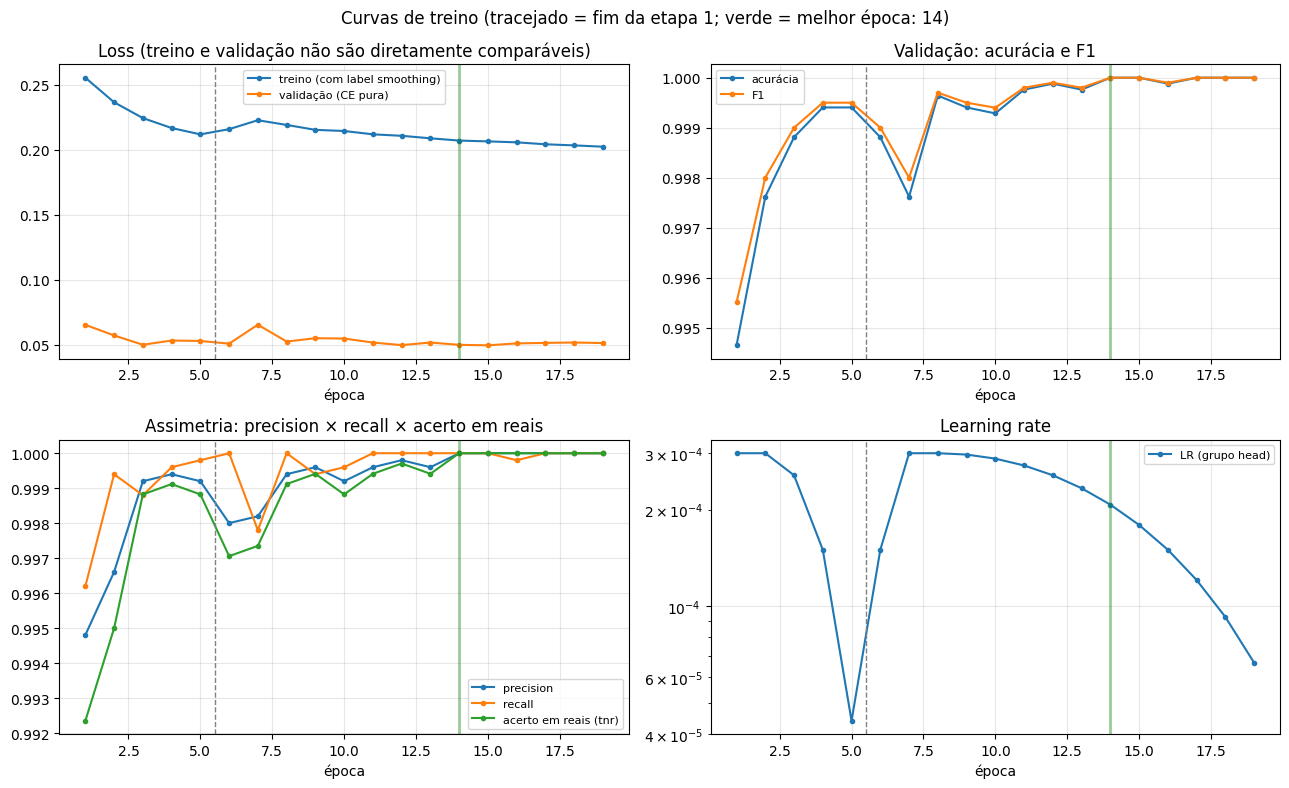

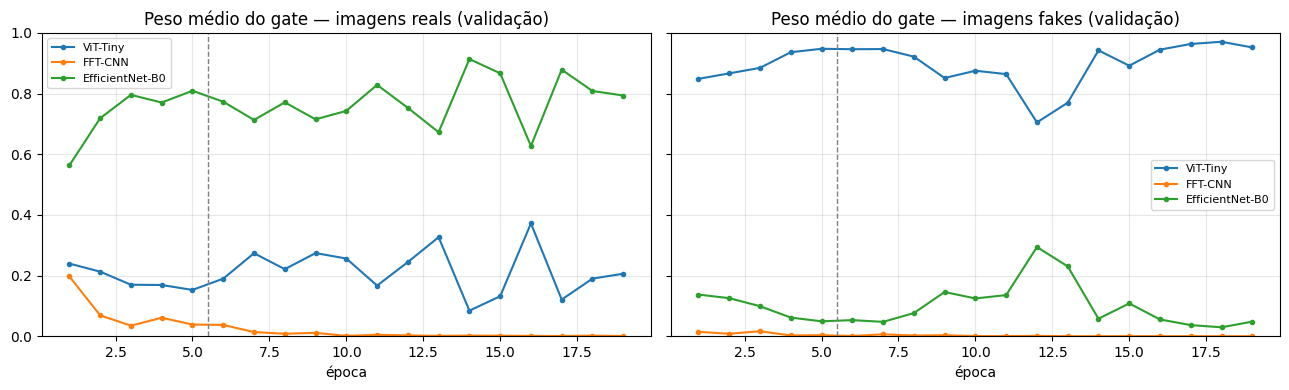

In [14]:
# Curvas de treino e gate por época (a partir do history)
hist = load_history()
_save(plot_training_curves(hist), "curvas_treino.png")
fig_ge = plot_gate_evolution(hist)
if fig_ge is not None:
    _save(fig_ge, "gate_por_epoca.png")

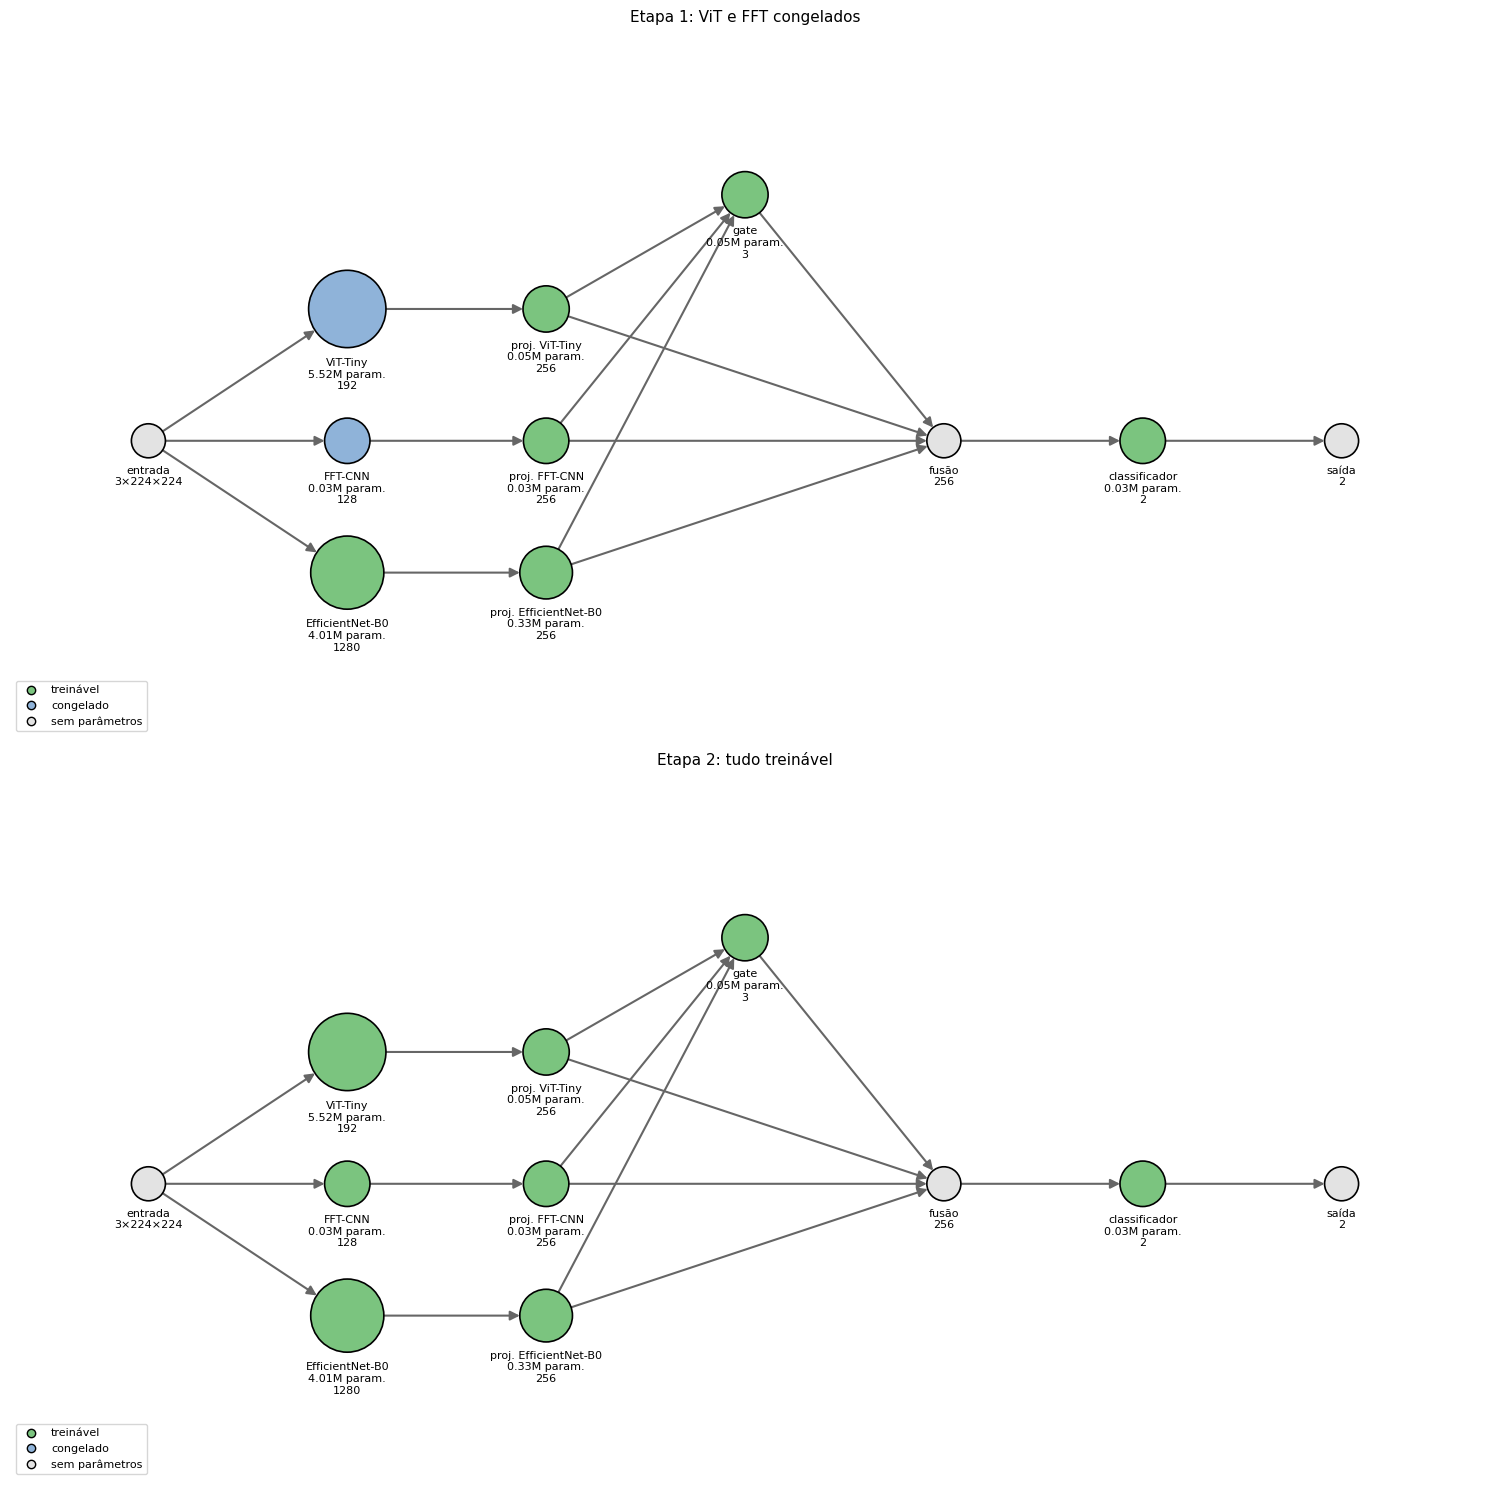

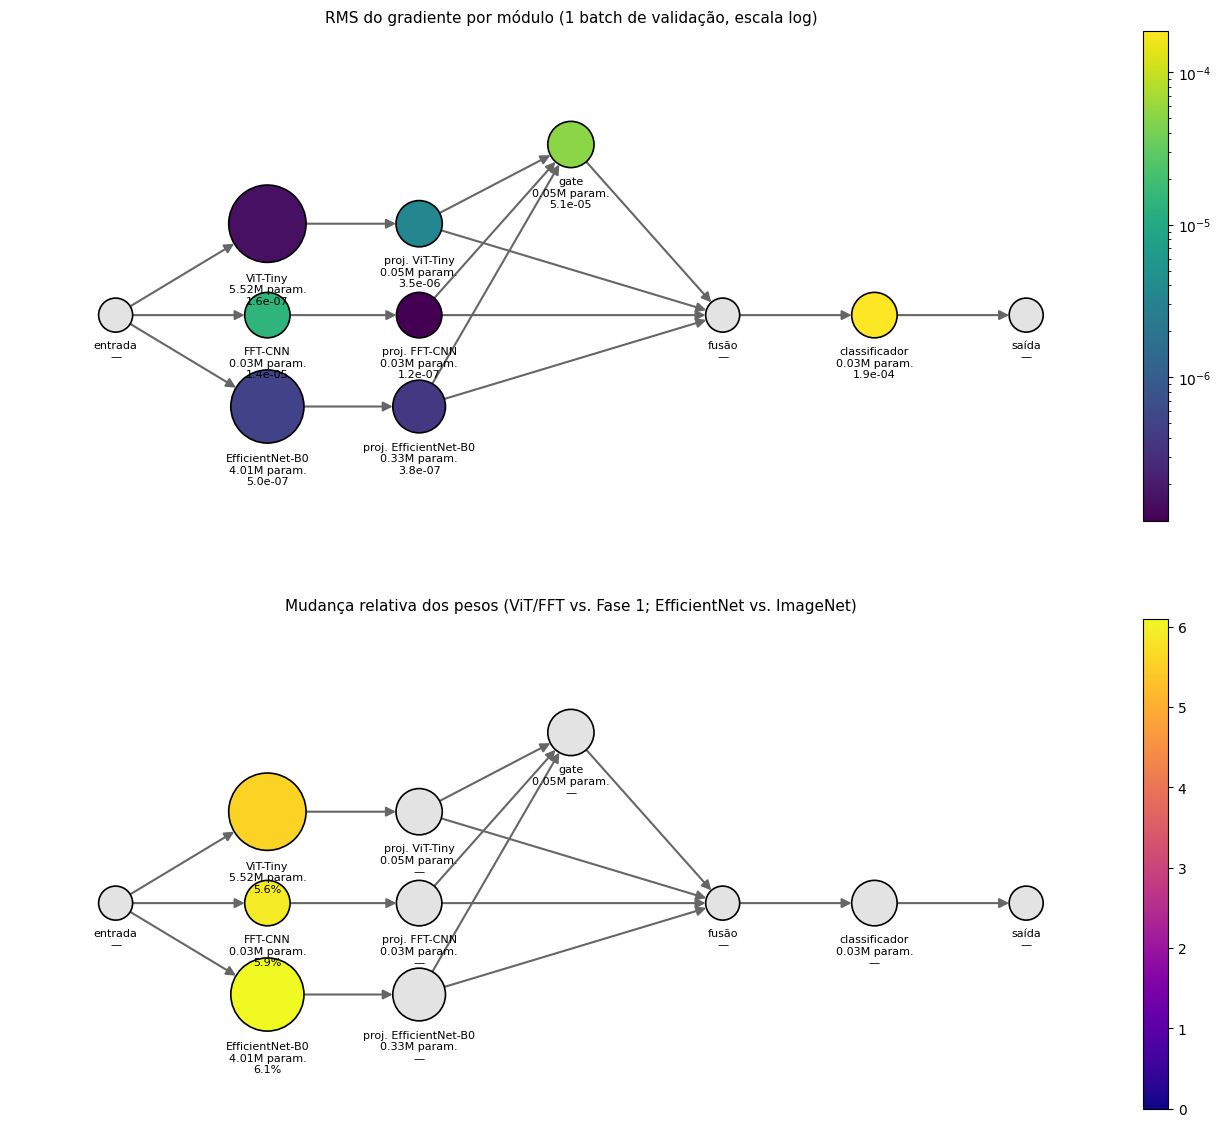

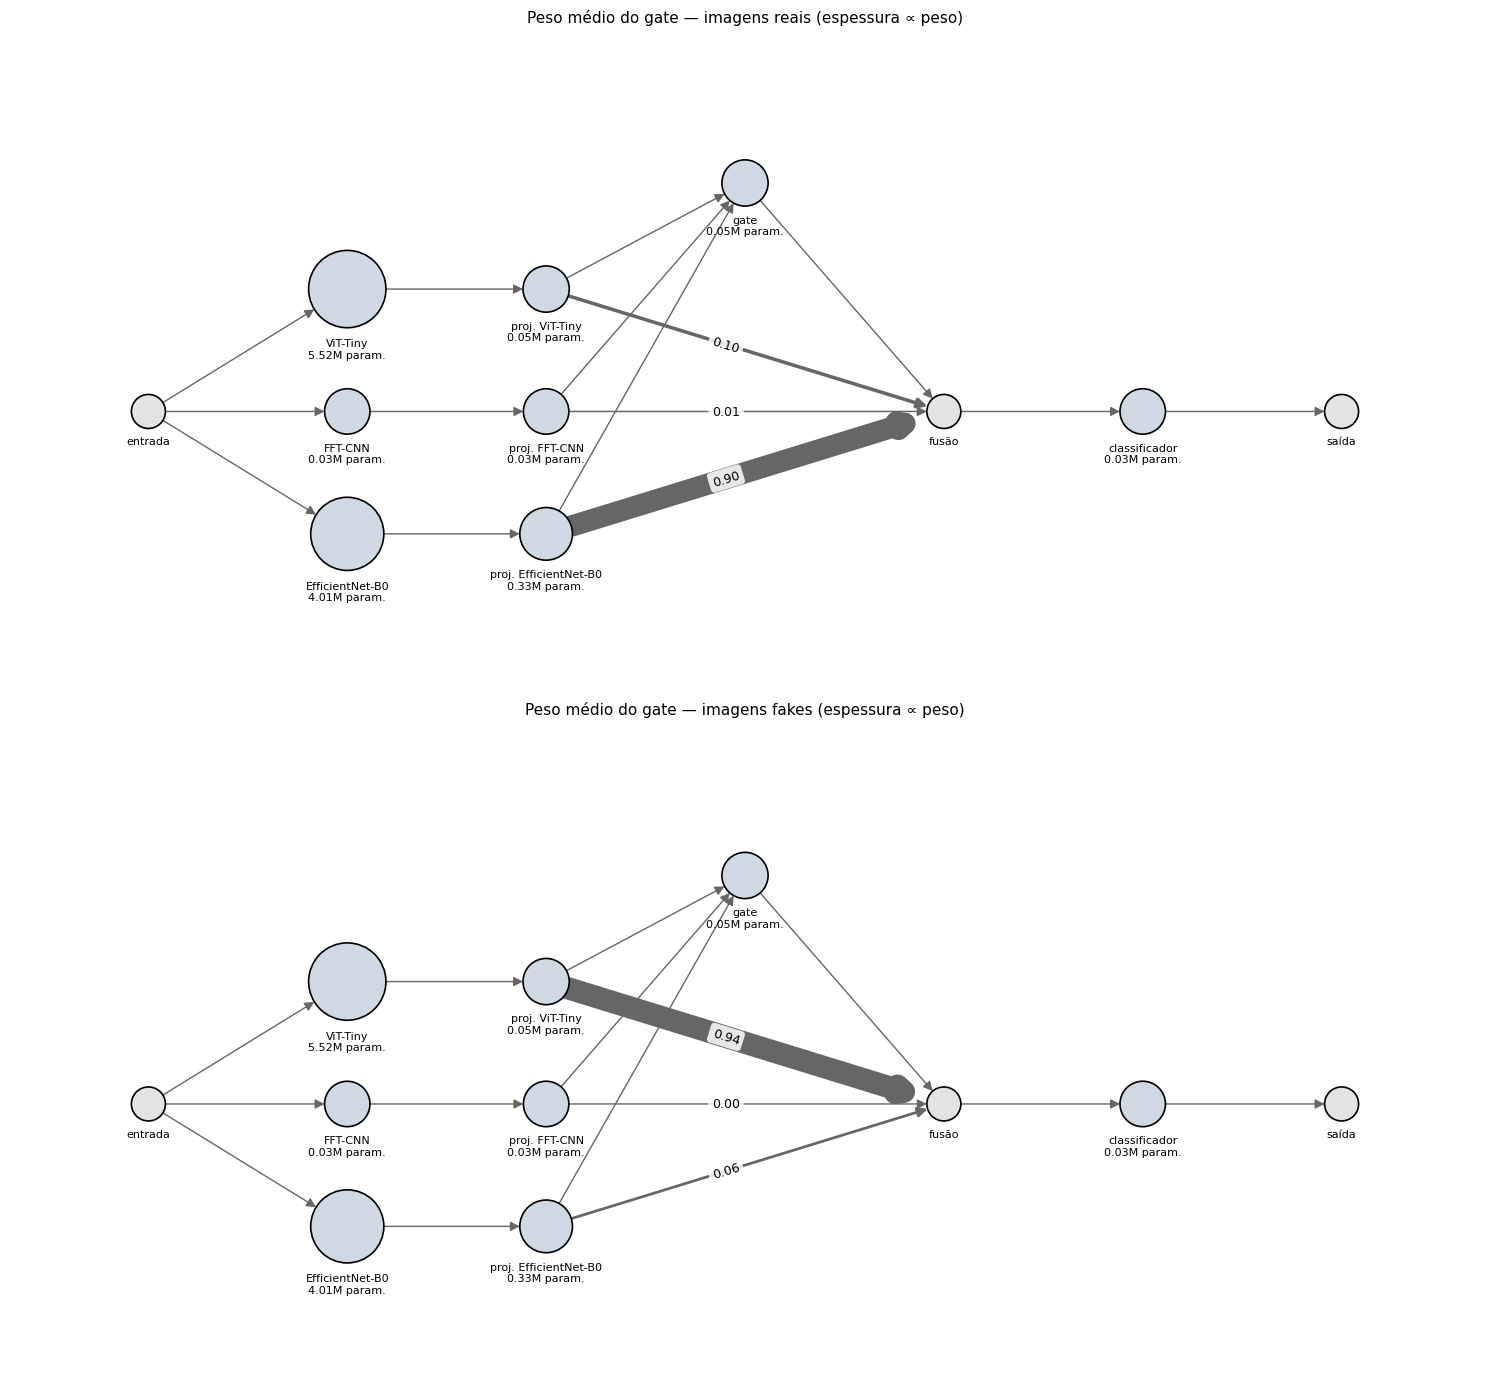

Figuras salvas em /content/drive/MyDrive/TCC_Final/modelos/fase2_gate_vit_fft_cnn/viz


In [15]:
# Grafo de módulos: topologia, saúde (gradiente e pesos) e gate real x fake
G = build_module_graph(model)
shapes = collect_shapes(model)
_save(fig_topology(G, shapes), "topologia.png")

grad = grad_rms_per_module(model, G, valid_es_loader)
delta = rel_change_vs_ref(model)
_save(fig_health(G, grad, delta), "saude_modulos.png")

if model.fusion == "gate":
    _save(fig_gate_graph(G, model, gate_means(model)), "gate_real_vs_fake.png")
else:
    print("Fusão 'concat': não há gate para visualizar.")
print("Figuras salvas em", VIZ_DIR)

### Próximos experimentos (cada um com um `RUN_NAME` novo)
- **Ablação do gate:** `FUSION="concat"`.
- **Ablação de branches:** `BRANCHES=("vit","fft")`, `("vit","cnn")`, `("fft","cnn")`.
- **Augmentations:** `AUG="freq_safe"` (sem rotação, JPEG mais leve) para testar o efeito no branch FFT.
- **Sem checkpoint da Fase 1:** `LOAD_PHASE1=False` (treino conjunto desde o início).
- **Análise de erros:** em `test_predictions.csv`, filtre `label=0` e `pred_thr=1` (falsos positivos) e veja os pesos do gate.